In [ ]:
import kagglehub

path = kagglehub.dataset_download("hojjatk/mnist-dataset")

print("Path to dataset files:", path)

100%|██████████| 22.0M/22.0M [00:00<00:00, 130MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/hojjatk/mnist-dataset/versions/1


Number of images: 60000
Image dimensions: 28 x 28
Array shape: (60000, 28, 28)


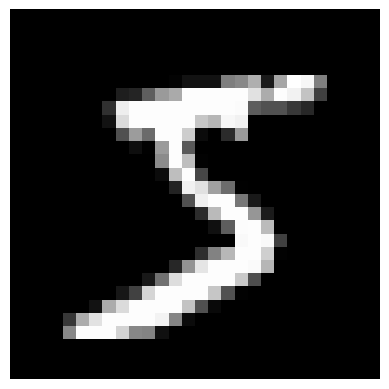

In [ ]:
import gzip
import struct
import numpy as np
import matplotlib.pyplot as plt

filename = path + "/train-images.idx3-ubyte"

with open(filename, "rb") as f:
    magic, num_images, rows, cols = struct.unpack(
        ">IIII", f.read(16)
    )

    images = np.frombuffer(
        f.read(), dtype=np.uint8
    ).reshape(num_images, rows, cols)

print("Number of images:", num_images)
print("Image dimensions:", rows, "x", cols)
print("Array shape:", images.shape)

plt.imshow(images[0], cmap="gray")
plt.axis("off")
plt.show()

In [ ]:
import os

os.listdir(path)

['train-images.idx3-ubyte',
 't10k-images-idx3-ubyte',
 't10k-images.idx3-ubyte',
 't10k-labels.idx1-ubyte',
 'train-images-idx3-ubyte',
 'train-labels-idx1-ubyte',
 'train-labels.idx1-ubyte',
 't10k-labels-idx1-ubyte']

In [ ]:
filename = path + "/train-labels.idx1-ubyte"

with open(filename, "rb") as f:
    # Read the header
    magic, num_labels = struct.unpack(">II", f.read(8))

    # Read all labels
    labels = np.frombuffer(f.read(), dtype=np.uint8)

print("Magic number:", magic)
print("Number of labels:", num_labels)
print("Labels shape:", labels.shape)
print("First 10 labels:", labels[:10])

Magic number: 2049
Number of labels: 60000
Labels shape: (60000,)
First 10 labels: [5 0 4 1 9 2 1 3 1 4]


In [ ]:
# Normalize images to [0, 1] range and split 80% (48,000) for training, 20% (12,000) for testing
images_normalized = images.reshape(60000, -1) / 255.0

X_train = images_normalized[0:48000]
X_test = images_normalized[48000:]
y_train = labels[0:48000]
y_test = labels[48000:]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (48000, 784)
X_test shape: (12000, 784)


In [ ]:
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Dense(units=784, input_shape=[784]),
    tf.keras.layers.Dense(units=1024, activation='relu'),
    tf.keras.layers.Dense(units=81, activation='relu'),
    tf.keras.layers.Dense(units=10, activation='softmax'),
])

model.compile(
    optimizer="sgd",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(X_train, y_train, epochs=60)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/60
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.8715 - loss: 0.4865
Epoch 2/60
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.9287 - loss: 0.2468
Epoch 3/60
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 25s 17ms/step - accuracy: 0.9437 - loss: 0.1941
Epoch 4/60
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 25s 17ms/step - accuracy: 0.9534 - loss: 0.1614
Epoch 5/60
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.9595 - loss: 0.1372
Epoch 6/60
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 41s 17ms/step - accuracy: 0.9659 - loss: 0.1191
Epoch 7/60
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 25s 17ms/step - accuracy: 0.9704 - loss: 0.1044
Epoch 8/60
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 25s 17ms/step - accuracy: 0.9738 - loss: 0.0925
Epoch 9/60
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 41s 17ms/step - accuracy: 0.9766 - loss: 0.0830
Epoch 10/60
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 25s 16ms/step - accuracy: 0.9791 - loss: 0.0748
Epoch 11/60
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 25s 17ms/step - accuracy: 0.9814 - loss: 0.0675
Epoch 12

In [ ]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test loss:", loss)
print("Test accuracy:", accuracy)

Test loss: 0.08055941015481949
Test accuracy: 0.9798333048820496


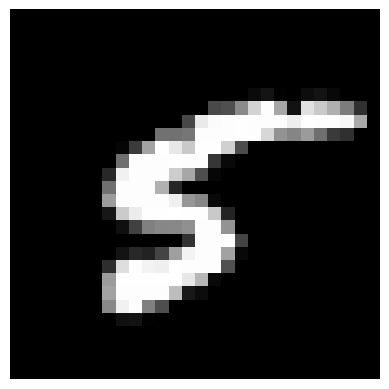

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
Predicted label: 5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Confidence scores:
 [[1.6762581e-07 2.9782038e-11 7.6435978e-09 1.6224118e-11 1.1497352e-09
  9.9979621e-01 1.8623473e-08 2.8309564e-09 2.0356236e-04 2.6292661e-09]]


In [ ]:
import random
idx = random.randint(1, X_test.shape[0])

plt.imshow((X_test[idx]*255).reshape(28, 28), cmap="gray")
plt.axis("off")
plt.show()
print("Predicted label:", np.argmax(model.predict(X_test[idx].reshape(1, -1))))
print("Confidence scores:\n", model.predict(X_test[idx].reshape(1, -1)))

In [ ]:
X_test.shape

(12000, 784)

In [ ]:
model.save("mnist_classifier.keras")